In [1]:
# Email Spam Detection using KNN and SVM

# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# 2. Load Dataset
data = pd.read_csv("emails.csv")

print("Dataset:")
print(data.head())

Dataset:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


In [3]:
# 3. Data Preprocessing
data = data.loc[:, ~data.columns.str.contains('^Unnamed')]
data = data.drop(columns=['Email No.'], errors='ignore')
data = data.drop_duplicates()
data = data.fillna(0)

X = data.drop('Prediction', axis=1)
y = data['Prediction']


In [4]:
# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [5]:
# 5. Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# 6. KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

print("\nKNN Results")
print("Accuracy:", accuracy_score(y_test, knn_pred) * 100, "%")
print("Confusion Matrix:\n", confusion_matrix(y_test, knn_pred))
print("Classification Report:\n", classification_report(y_test, knn_pred))


KNN Results
Accuracy: 84.68176914778857 %
Confusion Matrix:
 [[504 131]
 [ 11 281]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.79      0.88       635
           1       0.68      0.96      0.80       292

    accuracy                           0.85       927
   macro avg       0.83      0.88      0.84       927
weighted avg       0.89      0.85      0.85       927



In [7]:
# 7. SVM Classifier
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

print("\nSVM Results")
print("Accuracy:", accuracy_score(y_test, svm_pred) * 100, "%")
print("Confusion Matrix:\n", confusion_matrix(y_test, svm_pred))
print("Classification Report:\n", classification_report(y_test, svm_pred))



SVM Results
Accuracy: 93.6353829557713 %
Confusion Matrix:
 [[600  35]
 [ 24 268]]
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95       635
           1       0.88      0.92      0.90       292

    accuracy                           0.94       927
   macro avg       0.92      0.93      0.93       927
weighted avg       0.94      0.94      0.94       927



In [8]:
# 8. Performance Comparison
knn_acc = accuracy_score(y_test, knn_pred)
svm_acc = accuracy_score(y_test, svm_pred)

print("\nPerformance Comparison")
print("KNN Accuracy:", knn_acc * 100, "%")
print("SVM Accuracy:", svm_acc * 100, "%")


Performance Comparison
KNN Accuracy: 84.68176914778857 %
SVM Accuracy: 93.6353829557713 %


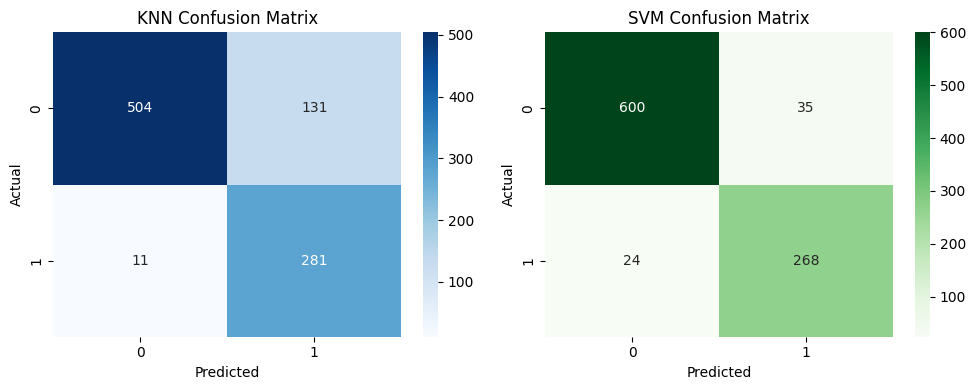

In [9]:
# 9. Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(y_test, knn_pred),
            annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, svm_pred),
            annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

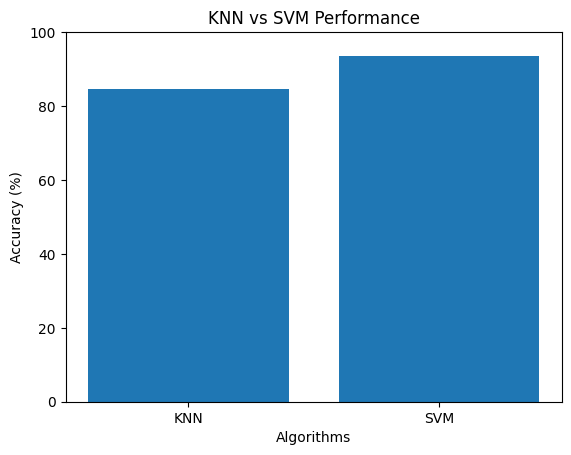

SVM performs better.


In [10]:
# 10. Accuracy Comparison Graph
plt.bar(['KNN', 'SVM'], [knn_acc * 100, svm_acc * 100])
plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")
plt.title("KNN vs SVM Performance")
plt.ylim(0, 100)
plt.show()

# 11. Final Result
if knn_acc > svm_acc:
    print("KNN performs better.")
elif svm_acc > knn_acc:
    print("SVM performs better.")
else:
    print("Both models have equal accuracy.")